# Planck modificado
### Física Electrónica - UTN FRA
*Cuaderno interactivo adaptado para Google Colab.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)


Text(0.5, 0, 'Frecuencia [$THz$]')

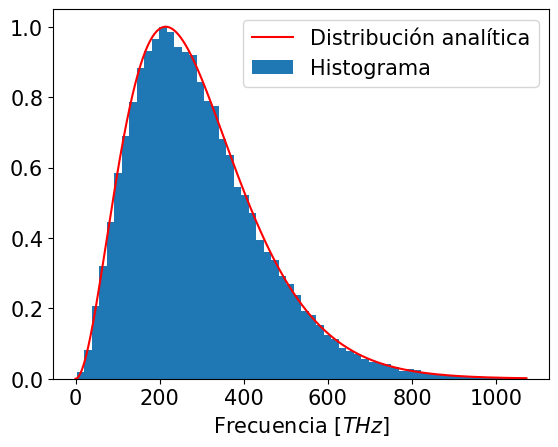

In [2]:
# -*- coding: utf-8 -*-
"""
Este es un ejemplo de código que utiliza funciones relacionadas con la ley de Planck y otras distribuciones.

"""
import numpy as np
import matplotlib.pyplot as plt
# desde Planck_functions import *
plt.close('all')

# Constantes
h = 6.6261e-34        # constante de Planck [Js]
c = 299792458               # velocidad de la luz [m/s]
k = 1.38064852e-23    # constante de Boltzmann [J/K]
b = 2.8977729e-3             # constante de desplazamiento de Wien [mK]

# -------- Ley de Planck --------
# Frecuencia
def planck_freq(freq, T):
    y = (2*h*freq**3)/(c**2)*(1/(np.exp(h*freq/(k*T))-1))   # radiación espectral [W/(sr m^2 Hz)]
    return y

# Longitud de onda
def planck_wave(wave, T):
    y = (2*h*c**2)/(wave**5)*(1/(np.exp(h*c/(wave*k*T))-1)) # radiación espectral [W/(sr m^3)]
    return y

# -------- Ley de Wien --------
# Frecuencia
def wien_freq(T):
    nu_max = 5.88e10*T
    return nu_max

# Longitud de onda
def wien_wave(T):
    lambda_max = b/T
    return lambda_max

# -------- Muestreo de Planck --------
def sampling(function,T,n):

    if function == planck_freq:
        # Frecuencia
        max_freq = 5*wien_freq(T)
        max_intensity = function(wien_freq(T), T)
        x_sampled = np.zeros(n)
        y_weight = np.zeros(n)
        i = 0
        samples = 0
        while i<n:
            x_random = np.random.uniform(1,max_freq)
            y_random = np.random.uniform(0,max_intensity)
            y_real = function(x_random, T)
            samples += 1
            if y_random<=y_real:
                x_sampled[i] = x_random
                y_weight[i] = 1
                i += 1
        return x_sampled

    elif function==planck_wave:
        # Longitud de onda
        max_wave = 5*wien_wave(T)
        max_intensity = function(wien_wave(T), T)
        x_sampled = np.zeros(n)
        y_weight = np.zeros(n)
        i = 0
        samples = 0
        while i<n:
            x_random = np.random.uniform(1e-10,max_wave)
            y_random = np.random.uniform(0,max_intensity)
            y_real = function(x_random, T)
            samples += 1
            if y_random<=y_real:
                x_sampled[i] = x_random
                y_weight[i] = 1
                i += 1
        return x_sampled
    else:
        return '¡La función de entrada debe ser planck_freq o planck_wave!'

# -------- Transformación incorrecta --------
def planckVSplanck(T):
    n = 10000
    nu_max = 5.88e10*T
    max_freq = 5*nu_max
    x_freq = np.linspace(1,max_freq,n)
    x_wave = c/x_freq

    fig,ax1 = plt.subplots()
    ax1.plot(x_freq, planck_freq(x_freq,T)/planck_freq(x_freq,T).max(),'r')
    ax1.set_xlabel('Frecuencia [Hz]', color='r')
    ax1.tick_params(axis='x', labelcolor='r')
    ax1.plot(x_freq, planck_wave(x_wave,T)/planck_wave(x_wave,T).max(),'b')
    return

# -------- Distribución de Maxwell-Boltzmann --------
def max_boltz(m,freq,T):
    f = 1/np.exp(m*h*freq/(k*T))
    return f

# -------- Muestreo de Maxwell-Boltzmann --------
def sampling_mb(freq_vector,T):
    m_tot = np.zeros(len(freq_vector))
    for i in range(len(freq_vector)):
        m_pair = np.zeros(2)
        l = 0
        while l<2:
            m_max = np.ceil(10*k*T/(h*freq_vector[i]))
            m_random = np.random.randint(0,m_max)
            f_random = np.random.uniform(0,1)
            f_real = max_boltz(m_random,freq_vector[i],T)
            if f_random<=f_real:
                m_pair[l] = m_random
                l += 1
        m_tot[i] = np.sum(m_pair)
    return m_tot

# -------- Densidad de energía --------
def u_freq(freq,T):
    u = (8*np.pi*h*freq**3)/(c**3)*1/(np.exp(h*freq/(k*T))-1)   # densidad de energía [J/(m^3 Hz)]
    return u

def u_wave(wave,T):
    u = (8*np.pi*h*c)/(wave**5)*1/(np.exp(h*c/(k*T*wave))-1)   # densidad de energía [J/m^4]
    return u

# -------- Muestreo de Planck --------
#T = int(input('For which temperature do you wish to see the Planck distribution? (Kelvin)'))
T = 3646  #@param {type: "slider", min: 100, max: 5000}
n = 48664  #@param {type: "slider", min: 100, max: 1000000}
planck = planck_freq    #planck_wave

if planck == planck_freq:
    wien = wien_freq
    lowlim = 1
    factor = 1/1e12
    xlabel = r'Frecuencia [$THz$]'
elif planck == planck_wave:
   wien = wien_wave
   lowlim = 1e-9
   factor = 1e9
   xlabel = r'Longitud de Onda [$nm$]'

plt.figure(1)
#histograma - normalizado, valor máximo 1
font = {'family':'DejaVu Sans','size' : 15}
plt.rc('font',**font)
x_max = 5*wien(T)
x_sampled = sampling(planck,T,n)
y_weight = np.ones(n)
plt.figure(1)
bins = 60
[histy, histx] = np.histogram(x_sampled, bins=bins, weights=y_weight)
x_bins = histx*factor
x_axis = 0.5*(x_bins[1:] + x_bins[:-1])
histy_norm = histy/max(histy)
plt.bar(x_axis, histy_norm, np.diff(x_bins), label = 'Histograma')

# gráfico analítico - normalizado, valor máximo 1
x_real = np.linspace(lowlim,x_max,n)
plt.plot(x_real*factor,planck(x_real, T)/planck(x_real, T).max(),'r-',label = 'Distribución analítica') #1e6*
plt.legend()
#plt.title('Distribución de Planck normalizada y histograma')
plt.xlabel(xlabel)


<ipython-input-2-35cf8fda33e8>:27: RuntimeWarning: overflow encountered in exp
  y = (2*h*c**2)/(wave**5)*(1/(np.exp(h*c/(wave*k*T))-1)) #spectral radiance [W/(sr m^3)]


Text(0.5, 0, 'Longitud de onda [$nm$]')

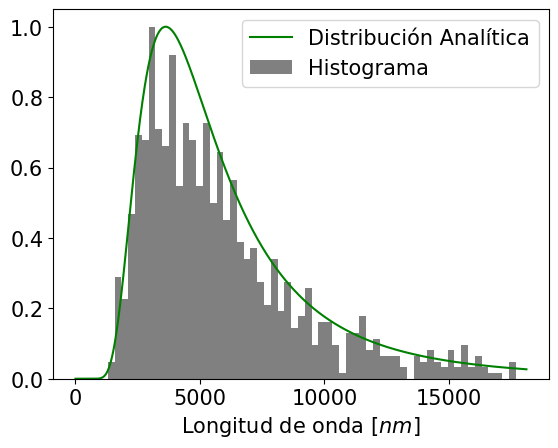

In [ ]:
#@title
# -*- coding: utf-8 -*-
"""
Created on Tue Apr 24 16:38:05 2018

@author: alice
"""
import numpy as np
import matplotlib.pyplot as plt
#from Planck_functions import *
plt.close('all')

#constants
h = 6.6261e-34        #planck's constant [Js]
c = 299792458               #speed of light [m/s]
k = 1.38064852e-23    #boltzmann's constant [J/K]
b = 2.8977729e-3             #wien's displacement constant [mK]

#--------planck's law--------
#frequency
def planck_freq(freq, T):
    y = (2*h*freq**3)/(c**2)*(1/(np.exp(h*freq/(k*T))-1))   #spectral radiance [W/(sr m^2 Hz)]
    return y

#wavelength
def planck_wave(wave, T):
    y = (2*h*c**2)/(wave**5)*(1/(np.exp(h*c/(wave*k*T))-1)) #spectral radiance [W/(sr m^3)]
    return y

#--------wien's law--------
#frequency
def wien_freq(T):
    nu_max = 5.88e10*T
    return nu_max

#wavelength
def wien_wave(T):
    lambda_max = b/T
    return lambda_max

#--------sampling planck--------
def sampling(function,T,n):


    if function == planck_freq:

#       frequency
        max_freq = 5*wien_freq(T)
        max_intensity = function(wien_freq(T), T)
        x_sampled = np.zeros(n)
        y_weight = np.zeros(n)
        i = 0
        samples = 0
        while i<n:
            x_random = np.random.uniform(1,max_freq)
            y_random = np.random.uniform(0,max_intensity)
            y_real = function(x_random, T)
            samples += 1
            if y_random<=y_real:
                x_sampled[i] = x_random
                y_weight[i] = 1
                i += 1
        return x_sampled


    elif function==planck_wave:

#       wavelength
        max_wave = 5*wien_wave(T)
        max_intensity = function(wien_wave(T), T)
        x_sampled = np.zeros(n)
        y_weight = np.zeros(n)
        i = 0
        samples = 0
        while i<n:
            x_random = np.random.uniform(1e-10,max_wave)
            y_random = np.random.uniform(0,max_intensity)
            y_real = function(x_random, T)
            samples += 1
            if y_random<=y_real:
                x_sampled[i] = x_random
                y_weight[i] = 1
                i += 1
        return x_sampled
    else:
        return 'Input function must be planck_freq or planck_wave!'


#--------incorrect transformation--------
def planckVSplanck(T):

    n = 10000

    nu_max = 5.88e10*T
    max_freq = 5*nu_max
    x_freq = np.linspace(1,max_freq,n)
    x_wave = c/x_freq

    fig,ax1 = plt.subplots()
    ax1.plot(x_freq, planck_freq(x_freq,T)/planck_freq(x_freq,T).max(),'r')
    ax1.set_xlabel('Frecuencia [Hz]', color='r')
    ax1.tick_params(axis='x', labelcolor='r')
    ax1.plot(x_freq, planck_wave(x_wave,T)/planck_wave(x_wave,T).max(),'b')
    return

#--------maxwell-boltzmann distribution--------
def max_boltz(m,freq,T):
    f = 1/np.exp(m*h*freq/(k*T))
    return f

#--------sampling maxwell-boltzmann--------
def sampling_mb(freq_vector,T):
    #m_sampled = np.zeros(len(freq_vector),dtype=np.ndarray)
    m_tot = np.zeros(len(freq_vector))
    for i in range(len(freq_vector)):
        m_pair = np.zeros(2)
        l = 0
        while l<2:
            m_max = np.ceil(10*k*T/(h*freq_vector[i]))
            m_random = np.random.randint(0,m_max)
            f_random = np.random.uniform(0,1)
            f_real = max_boltz(m_random,freq_vector[i],T)
            if f_random<=f_real:
                m_pair[l] = m_random
                l += 1
       # m_sampled[i] = m_pair
        m_tot[i] = np.sum(m_pair)
    return m_tot

#--------energy density--------
def u_freq(freq,T):
    u = (8*np.pi*h*freq**3)/(c**3)*1/(np.exp(h*freq/(k*T))-1)   #energy density [J/(m^3 Hz)]
    return u

def u_wave(wave,T):
    u = (8*np.pi*h*c)/(wave**5)*1/(np.exp(h*c/(k*T*wave))-1)   #energy density [J/m^4]
    return u
#T = int(input('For which temperature do you wish to see the Planck distribution? (Kelvin)'))



#--------Sampling from Planck---------
T = 800
n = 1000

#freq or wavelength
planck = planck_wave    #planck_wave

if planck == planck_freq:
    wien = wien_freq
    lowlim = 1
    factor = 1/1e12
    xlabel = r'Frecuencia [$THz$]'
elif planck == planck_wave:
   wien = wien_wave
   lowlim = 1e-9
   factor = 1e9
   xlabel = r'Longitud de onda [$nm$]'

plt.figure(1)
#histogram - normalized, maximum value 1
font = {'family':'DejaVu Sans','size' : 15}
plt.rc('font',**font)
x_max = 5*wien(T)
x_sampled = sampling(planck,T,n)
y_weight = np.ones(n)
plt.figure(1)
bins = 60
[histy, histx] = np.histogram(x_sampled, bins=bins, weights=y_weight)
x_bins = histx*factor
x_axis = 0.5*(x_bins[1:] + x_bins[:-1])
histy_norm = histy/max(histy)
plt.bar(x_axis, histy_norm, np.diff(x_bins), label='Histograma', color='gray')


#analytical plot - normalized, maximum value 1
x_real = np.linspace(lowlim,x_max,n)  #ta 1 för freq, 1e-9 wave
plt.plot(x_real*factor,planck(x_real, T)/planck(x_real, T).max(),'g-',label = 'Distribución Analítica') #1e6*
plt.legend()
#plt.title('Normalized Planck distribution and histogram')
plt.xlabel(xlabel)
